In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import seaborn as sns
from sklearn import metrics

In [3]:
df = pd.read_csv("insurance.csv")

In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
df.shape

(1338, 7)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [8]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [9]:
df.head(5)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [10]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

C:\Users\kulal\AppData\Local\Temp\ipykernel_7272\2622995294.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['age'])


Text(0.5, 1.0, 'age distribution')

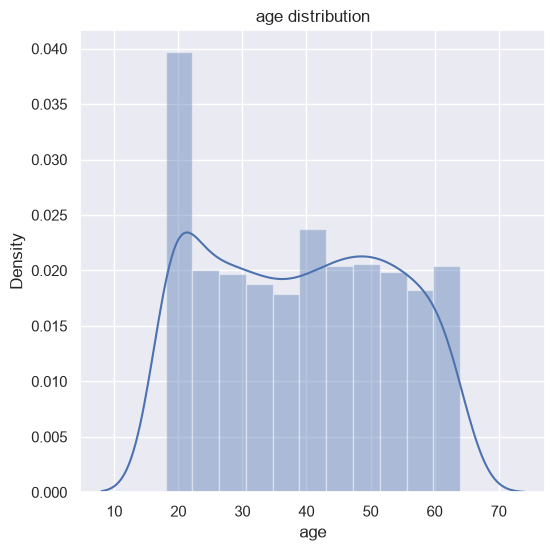

In [13]:
sns.set()
plt.figure(figsize=(6,6))
sns.distplot(df['age'])
plt.title('age distribution')


Text(0.5, 1.0, 'sex distribution')

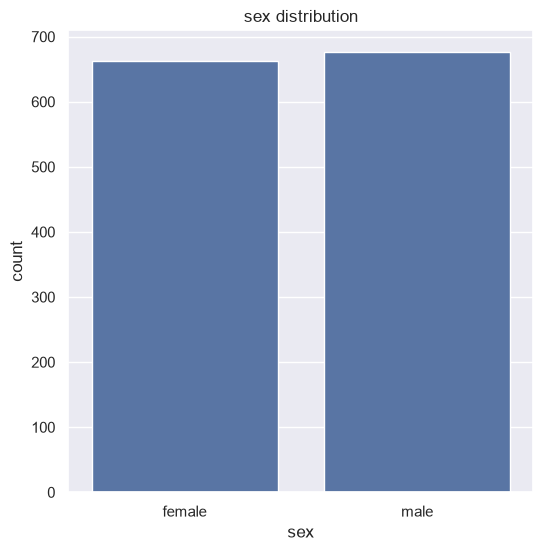

In [15]:
plt.figure(figsize=(6,6))
sns.countplot(x='sex',data=df)
plt.title("sex distribution")


In [16]:
df['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

C:\Users\kulal\AppData\Local\Temp\ipykernel_7272\3020372778.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['bmi'])


Text(0.5, 1.0, 'age distribution')

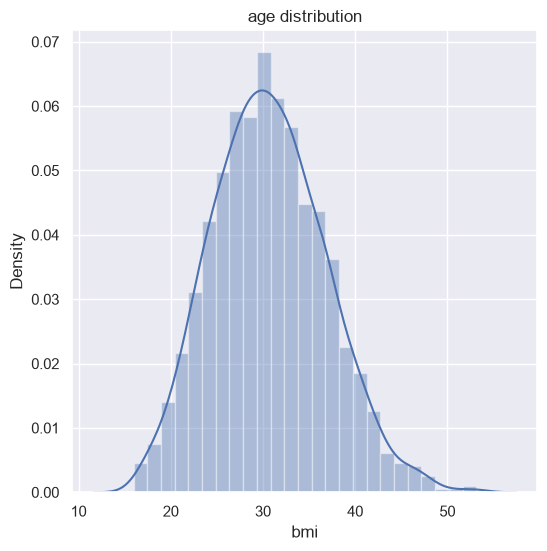

In [17]:
plt.figure(figsize=(6,6))
sns.distplot(df['bmi'])
plt.title('age distribution')


Text(0.5, 1.0, 'sex distribution')

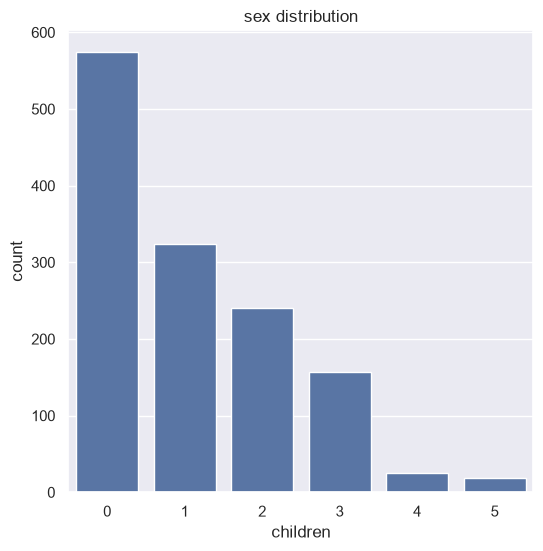

In [18]:
plt.figure(figsize=(6,6))
sns.countplot(x='children',data=df)
plt.title("sex distribution")


In [19]:
df['children'].value_counts()

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

Text(0.5, 1.0, 'sex distribution')

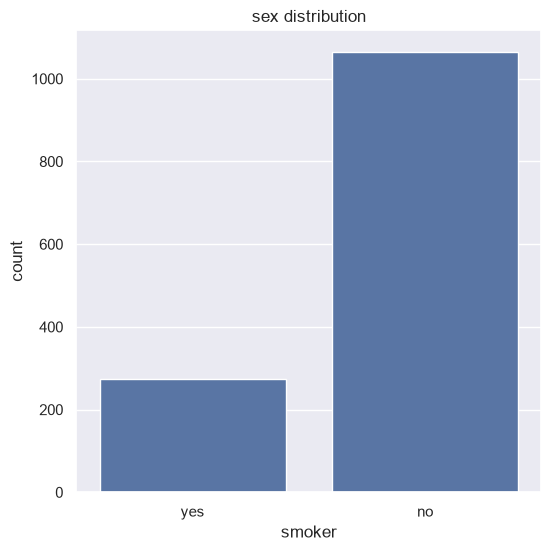

In [20]:
plt.figure(figsize=(6,6))
sns.countplot(x='smoker',data=df)
plt.title("sex distribution")

In [21]:
df['smoker'].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

Text(0.5, 1.0, 'sex distribution')

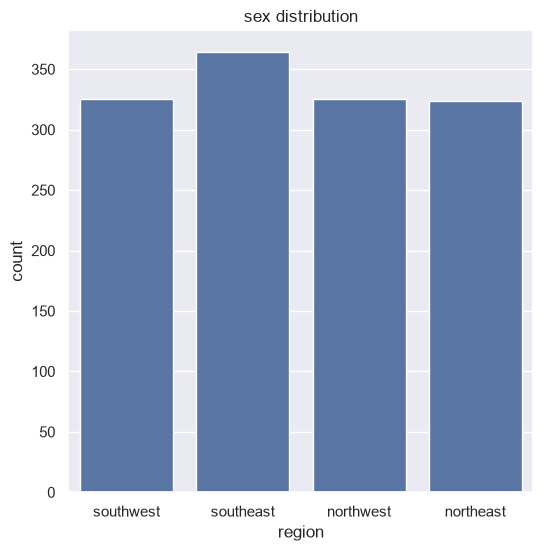

In [22]:
plt.figure(figsize=(6,6))
sns.countplot(x='region',data=df)
plt.title("sex distribution")

In [23]:
df['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

C:\Users\kulal\AppData\Local\Temp\ipykernel_7272\1819074535.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['charges'])


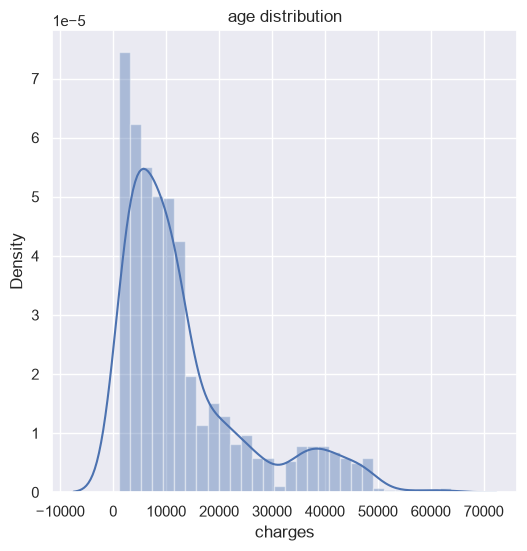

In [24]:
sns.set()
plt.figure(figsize=(6,6))
sns.distplot(df['charges'])

plt.title('age distribution')
plt.show()

In [36]:
#encodning the categorical feature

df.replace({'sex':{'male':0,'female':1}},inplace=True)

df.replace({'smoker':{"yes":0,"no":1}},inplace=True)

df.replace({'region':{'southeast':0,'southwest':1,'northeast':2,'northwest':3}},inplace=True)

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,0,1,16884.92400
1,18,0,33.770,1,1,0,1725.55230
2,28,0,33.000,3,1,0,4449.46200
3,33,0,22.705,0,1,3,21984.47061
4,32,0,28.880,0,1,3,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,1,3,10600.54830
1334,18,1,31.920,0,1,2,2205.98080
1335,18,1,36.850,0,1,0,1629.83350
1336,21,1,25.800,0,1,1,2007.94500


In [37]:
x = df.drop('charges',axis=1)
y = df['charges']

In [38]:
x

,age,sex,bmi,children,smoker,region
0,19,1,27.900,0,0,1
1,18,0,33.770,1,1,0
2,28,0,33.000,3,1,0
3,33,0,22.705,0,1,3
4,32,0,28.880,0,1,3
...,...,...,...,...,...,...
1333,50,0,30.970,3,1,3
1334,18,1,31.920,0,1,2
1335,18,1,36.850,0,1,0
1336,21,1,25.800,0,1,1


In [39]:
y

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1338, dtype: float64

In [40]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=2)

In [41]:
print(x_train.shape,x_test.shape,x.shape)

(1070, 6) (268, 6) (1338, 6)


In [42]:
x_train

,age,sex,bmi,children,smoker,region
882,21,1,22.135,0,1,2
505,37,0,30.875,3,1,3
798,58,1,33.100,0,1,1
792,22,1,23.180,0,1,2
201,48,1,32.230,1,1,0
...,...,...,...,...,...,...
466,60,1,28.700,1,1,1
299,48,1,28.880,1,1,3
493,61,0,43.400,0,1,1
527,51,1,25.800,1,1,1


In [43]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error
lr = LinearRegression()
lr.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 251.41, 26.12, 330.65, 580.27,-23928.1 , 212.22]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.136e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [45]:
y_pred = lr.predict(x_test)

score = r2_score(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)

print(score)
print(mae)

0.7447273869684077
4267.213826730733


In [46]:
from sklearn.ensemble import RandomForestRegressor

In [84]:
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42
)

In [85]:
rf.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease 

In [86]:
y_rf_pred = rf.predict(x_test)

In [87]:
score = r2_score(y_test,y_rf_pred)
mae = mean_absolute_error(y_test,y_rf_pred)

print(score)
print(mae)

0.8519078220831104
2828.919808475467


In [88]:
train_pred = rf.predict(x_train)
test_pred = rf.predict(x_test)

print("Train R2:", r2_score(y_train, train_pred))
print("Test R2 :", r2_score(y_test, test_pred))

Train R2: 0.9230540934581322
Test R2 : 0.8519078220831104


In [89]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    rf,
    x,
    y,
    cv=5,
    scoring='r2'
)

print(scores)
print("Mean CV R2:", scores.mean())

[0.86911352 0.80106938 0.87057514 0.83763595 0.85266912]
Mean CV R2: 0.8462126204023075


In [91]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

MAE: 4267.213826730733
RMSE: 6191.690842285234


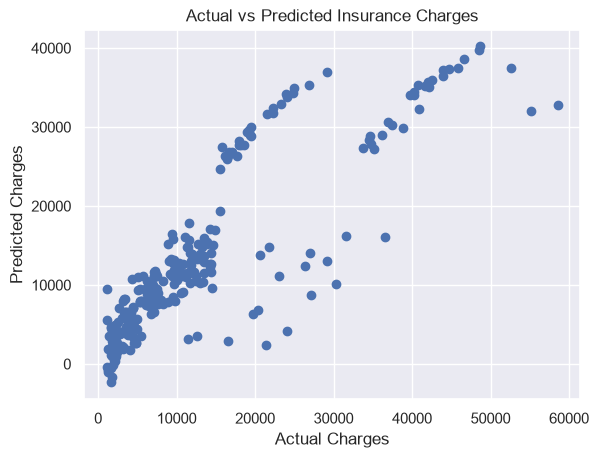

In [92]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Insurance Charges")

plt.show()

In [94]:
results = x_test.copy()

results['actual'] = y_test
results['predicted'] = y_pred

results['error'] = results['actual'] - results['predicted']
results['absolute_error'] = abs(results['error'])

results.sort_values(
    'absolute_error',
    ascending=False
).head(15)

,age,sex,bmi,children,smoker,region,actual,predicted,error,absolute_error
577,31,1,38.095,1,0,2,58571.07448,32778.037445,25793.037035,25793.037035
819,33,1,35.530,0,0,3,55135.40209,32064.687791,23070.714299,23070.714299
1012,61,1,33.330,4,1,0,36580.28216,16132.937727,20447.344433,20447.344433
387,50,0,25.365,2,1,3,30284.64294,10183.884392,20100.758548,20100.758548
526,19,1,30.590,2,1,3,24059.68019,4144.070063,19915.610127,19915.610127
102,18,1,30.115,0,1,2,21344.84670,2362.836721,18982.009979,18982.009979
1142,52,1,24.860,0,1,0,27117.99378,8748.619331,18369.374449,18369.374449
696,53,1,32.300,2,1,2,29186.48236,13045.027078,16141.455282,16141.455282
573,62,1,36.860,1,1,2,31620.00106,16235.146247,15384.854813,15384.854813
1146,60,0,32.800,0,0,1,52590.82939,37499.399475,15091.429915,15091.429915


In [96]:
results.sort_values(
    'absolute_error',
    ascending=False
)[[
    'age',
    'bmi',
    'children',
    'actual',
    'predicted',
    'error',
    'absolute_error'
]].head(15)

,age,bmi,children,actual,predicted,error,absolute_error
577,31,38.095,1,58571.07448,32778.037445,25793.037035,25793.037035
819,33,35.530,0,55135.40209,32064.687791,23070.714299,23070.714299
1012,61,33.330,4,36580.28216,16132.937727,20447.344433,20447.344433
387,50,25.365,2,30284.64294,10183.884392,20100.758548,20100.758548
526,19,30.590,2,24059.68019,4144.070063,19915.610127,19915.610127
102,18,30.115,0,21344.84670,2362.836721,18982.009979,18982.009979
1142,52,24.860,0,27117.99378,8748.619331,18369.374449,18369.374449
696,53,32.300,2,29186.48236,13045.027078,16141.455282,16141.455282
573,62,36.860,1,31620.00106,16235.146247,15384.854813,15384.854813
1146,60,32.800,0,52590.82939,37499.399475,15091.429915,15091.429915


In [97]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,0,1,16884.92400
1,18,0,33.770,1,1,0,1725.55230
2,28,0,33.000,3,1,0,4449.46200
3,33,0,22.705,0,1,3,21984.47061
4,32,0,28.880,0,1,3,3866.85520


In [100]:
df['smoker_binary'] = (df['smoker'] == 'yes').astype(int)

df['bmi_smoker'] = df['bmi'] * df['smoker_binary']

In [101]:
df.drop('bmi_smoker',axis=1,inplace=True)

In [102]:
df.head()

,age,sex,bmi,children,smoker,region,charges,smoker_binary
0,19,1,27.900,0,0,1,16884.92400,0
1,18,0,33.770,1,1,0,1725.55230,0
2,28,0,33.000,3,1,0,4449.46200,0
3,33,0,22.705,0,1,3,21984.47061,0
4,32,0,28.880,0,1,3,3866.85520,0


In [103]:
df['bmi_high'] = (df['bmi'] > 30).astype(int)

In [104]:
df['bmi_high_smoker'] = (
    (df['bmi'] > 30) & (df['smoker'] == 'yes')
).astype(int)

In [105]:
df.head()

,age,sex,bmi,children,smoker,region,charges,smoker_binary,bmi_high,bmi_high_smoker
0,19,1,27.900,0,0,1,16884.92400,0,0,0
1,18,0,33.770,1,1,0,1725.55230,0,1,0
2,28,0,33.000,3,1,0,4449.46200,0,1,0
3,33,0,22.705,0,1,3,21984.47061,0,0,0
4,32,0,28.880,0,1,3,3866.85520,0,0,0


In [107]:
x = df.drop("charges",axis=1)
y = df["charges"]

In [108]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=2)

In [109]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error
lr = LinearRegression()
lr.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[ 252.33, 30.92, 164.3 ,..., 0. ,2476.75, 0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['age','sex','bmi',...,'smoker_binary','bmi_high','bmi_high_smoker']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.518e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [110]:
y_pred = lr.predict(x_test)

score = r2_score(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)

print(score)
print(mae)

0.7552611432052045
4291.189723160438
